## <img src="logo_UNSAM.jpg" align="right" width="300" height="300"> *Análisis y precesamiento de señales*  
<h3 style="font-weight: normal;">Alumnos: Joaquín Rios, Sebastían Ceballes, Tomás Ladiani</h3>
&nbsp;
&nbsp;

# |  Trabajo Semanal N°7 : Filtrado diginal lineal de ECG

### **Introducción y Objetivos**
El electrocardiograma (ECG) registra la actividad eléctrica del miocardio a lo largo del ciclo cardíaco (ondas P, complejo QRS y onda T). Cuando este registro se adquiere durante una **prueba de esfuerzo**, la señal fisiológica se ve superpuesta con múltiples fuentes de contaminación que degradan la relación señal-ruido (SNR) y dificultan la interpretación clínica o la detección automática de eventos:

1. **Deriva de la línea base (*Baseline Wander*):** Perturbación de muy baja frecuencia ($f < 1\text{ Hz}$) originada principalmente por el ciclo respiratorio, la sudoración y los cambios en la impedancia piel-electrodo. Desplaza el nivel isoeléctrico respecto de cero.
2. **Ruido electromiográfico (EMG) y artefactos de movimiento:** Interferencias estocásticas de banda ancha con fuerte componente de alta frecuencia ($f > 30\text{–}40\text{ Hz}$), generadas por la contracción muscular del paciente durante el ejercicio físico y el desplazamiento mecánico de los electrodos.

El objetivo de este trabajo es diseñar, implementar y evaluar **filtros digitales lineales pasabanda** en Python ( Mediante comandos de `scipy.signal`) sobre un registro muestreado a $f_s = 1000\text{ Hz}$, buscando atenuar eficazmente ambas bandas de interferencia sin distorsionar la morfología ni la amplitud de los latidos normales y ventriculares.

### **Fundamentos Teóricos del Filtrado Digital**

Un sistema lineal e invariante en el tiempo (LTI) discreto queda completamente caracterizado por su función de transferencia en el dominio $Z$, $H(z)$, y su respuesta en frecuencia $H(e^{j\omega})$. 

Según su estructura interna, los filtros digitales se dividen en dos grandes familias:

#### Filtros FIR (*Finite Impulse Response*)
Son sistemas no recursivos cuya salida $y[n]$ depende únicamente de una combinación lineal ponderada de las muestras presentes y pasadas de la entrada $x[n]$:

$$y[n] = \sum_{k=0}^{M} b_k \, x[n-k]$$

* **Estabilidad:** Al no poseer realimentación ($a_l = 0$ para $l \ge 1$), todos sus polos se ubican en el origen ($z = 0$), garantizando estabilidad incondicional.
* **Linealidad de fase:** Si los coeficientes $b_k$ presentan simetría par o impar respecto del punto medio, el filtro posee **fase estrictamente lineal**, lo que implica un **retardo de grupo constante** ($\tau_g(\omega) = -\frac{d\phi(\omega)}{d\omega} = \frac{M}{2}$ muestras) para todas las frecuencias. Esto evita la dispersión de fase y preserva la forma de onda original.
* **Costo computacional:** Para lograr bandas de transición angostas (especialmente en bajas frecuencias respecto de $f_s$), requieren un orden $M$ elevado. Entre las metodologías de diseño abordadas se encuentran el **enventanado** (`firwin2`), **cuadrados mínimos** (`firls`) y el algoritmo equi-rizado de **Parks-McClellan / Remez** (`remez`).

#### Filtros IIR (*Infinite Impulse Response*)
Son sistemas recursivos que incorporan realimentación de salidas anteriores, regidos por la ecuación en diferencias:

$$y[n] = \sum_{k=0}^{M} b_k \, x[n-k] - \sum_{l=1}^{N} a_l \, y[n-l]$$

* **Selectividad y orden:** Gracias a la presencia de polos fuera del origen, alcanzan pendientes de atenuación pronunciadas con un orden $N$ significativamente menor al de un FIR equivalente. Aproximaciones clásicas como **Butterworth** (máxima planicidad) y **Cauer/Elíptico** (equi-rizado en ambas bandas) permiten cumplir plantillas exigentes con bajo costo computacional.
* **Estabilidad numérica (Formato SOS):** En filtros de orden moderado o alto con frecuencias de corte muy bajas respecto de $f_s$, la implementación directa mediante polinomios $(b, a)$ es sensible a errores de cuantificación. Para evitar inestabilidades numéricas, se emplea la descomposición en cascada de **Secciones de Segundo Orden (`sos`)**.
* **Distorsión de fase:** Los filtros IIR presentan una respuesta de fase no lineal, generando variaciones pronunciadas del retardo de grupo en las proximidades de las frecuencias de corte. En una aplicación causal directa, esto deformaría la morfología del complejo QRS y los segmentos ST.

### **Filtrado Bidireccional de Fase Nula (*Zero-Phase Filtering*)**

Dado que el análisis se realiza sobre un registro previamente almacenado (*offline*), es posible anular la distorsión de fase de los filtros IIR (y eliminar el retardo puro de los FIR) aplicando el filtrado en ambos sentidos temporales mediante las funciones `sosfiltfilt` y `filtfilt`:

1. Se filtra la señal original $x[n]$ en sentido directo ($n = 0 \to N-1$).
2. Se invierte temporalmente la secuencia resultante y se vuelve a filtrar con el mismo sistema.
3. Se invierte nuevamente el resultado final.

Matemáticamente, la respuesta en frecuencia global del proceso equivale a:

$$H_{\text{total}}(e^{j\omega}) = H(e^{j\omega}) \cdot H^*(e^{j\omega}) = \left|H(e^{j\omega})\right|^2$$

Este procedimiento produce **fase exactamente nula** ($\phi_{\text{total}}(\omega) = 0$) y retardo de grupo cero en todo el espectro, manteniendo alineados temporalmente todos los eventos cardíacos. Como contrapartida, la magnitud en decibeles se duplica ($\left|H_{\text{total}}\right|_{\text{dB}} = 2 \cdot \left|H\right|_{\text{dB}}$), duplicando tanto la atenuación en banda de rechazo como el rizado en banda pasante. Asimismo, todo truncamiento abrupto del espectro de alta frecuencia introduce oscilaciones transitorias adyacentes a los picos pronunciados (fenómeno de Gibbs o *ringing*), compromiso que se evaluará cuantitativa y cualitativamente en las distintas regiones del registro.

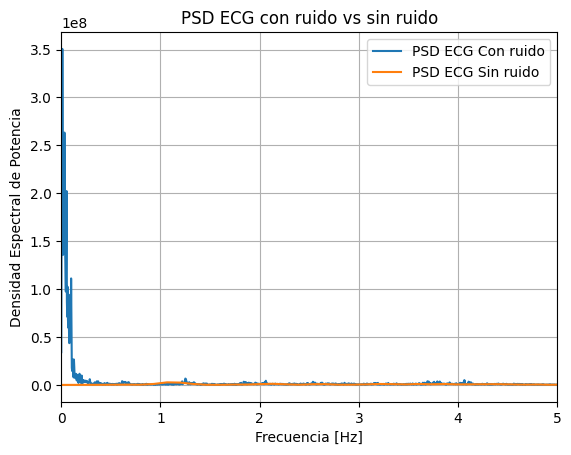

In [4]:
#%% Librerías
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal as sig
import scipy.io as sio
from matplotlib.patches import Rectangle

#%% Comparación de frecuencias con ECG limpia 

## ECG con ruido
fs_ecg = 1000  # Hz

# ecg: este ecg es un int16 [N,1] --> aplanarlo con un array de N
# para listar las variables que hay en el archivo
sio.whosmat('ECG_TP4.mat')
mat_struct = sio.loadmat('./ECG_TP4.mat')

ecg_one_lead = mat_struct['ecg_lead'].flatten() * 1.0
N = len(ecg_one_lead)

hb_1 = mat_struct['heartbeat_pattern1']
hb_2 = mat_struct['heartbeat_pattern2']

##psd con ruido
frec, x_ecg_welch = sig.welch(ecg_one_lead, fs=fs_ecg, nperseg=N/4)

## ECG sin ruido
ecg_one_lead1 = np.load('ecg_sin_ruido.npy')

N1 = len(ecg_one_lead1)

frec1, x_ecg_welch1 = sig.welch(ecg_one_lead1, fs=fs_ecg, nperseg=N1/4)


# ECG - Gráfico Original
plt.figure()
plt.title('PSD ECG con ruido vs sin ruido')
plt.plot(frec,x_ecg_welch, label='PSD ECG Con ruido')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Densidad Espectral de Potencia')
plt.plot(frec1,x_ecg_welch1, label="PSD ECG Sin ruido")
plt.grid()
plt.legend()
plt.xlim(0, 5)


plt.show()



#A partir del analisis comparativo entre las psd de la ECG
#sin ruido(analizada en la TS5) y de la ECG con ruido, se 
#determina que las bandas de rechazo serán de 0 a 0.1 Hz y
#de 35Hz a Nyquist y la banda pasante será de 1 a 25Hz



### **Determinación de la Plantilla de Diseño (Puntos a y b)**

Para establecer las frecuencias de corte y las tolerancias de atenuación del filtro pasabanda, se contrastó la Densidad Espectral de Potencia (PSD) estimada mediante el método de Welch del registro contaminado (`ecg_lead`) frente a la señal limpia reconstruida en la Tarea Semanal 5 (`ecg_sin_ruido.npy`), cuyo ancho de banda al 90% de energía acumulada se había estimado en $19.47\text{ Hz}$:

1. **Banda de rechazo inferior ($0\text{ Hz}$ a $w_{s1} = 0.5\text{ Hz}$):** En el espectro del registro ruidoso se observa una elevada concentración de energía por debajo de $0.5\text{ Hz}$ asociada a la deriva de la línea de base por respiración y movimiento de electrodos. Se fija $w_{s1} = 0.5\text{ Hz}$ para suprimir esta componente.
2. **Banda pasante ($w_{p1} = 1\text{ Hz}$ a $w_{p2} = 35\text{ Hz}$):** El límite inferior en $1\text{ Hz}$ preserva la frecuencia cardíaca fundamental y el contenido espectral lento de las ondas P y T. El límite superior en $35\text{ Hz}$ abarca la totalidad del ancho de banda útil estimado en la TS5 con margen suficiente para evitar la atenuación de los picos R.
3. **Banda de rechazo superior ($w_{s2} = 40\text{ Hz}$ a $f_{\text{nyq}} = 500\text{ Hz}$):** A partir de los $40\text{ Hz}$ el espectro útil del ECG decae significativamente mientras persiste el piso de ruido electromiográfico (EMG).
4. **Tolerancias de módulo ($\alpha_p = 1\text{ dB}$, $\alpha_s = 60\text{ dB}$):** Se impone un rizado máximo de $1\text{ dB}$ en banda pasante para mantener la fidelidad morfológica y una atenuación mínima de $60\text{ dB}$ en rechazo para garantizar una supresión efectiva de las interferencias.

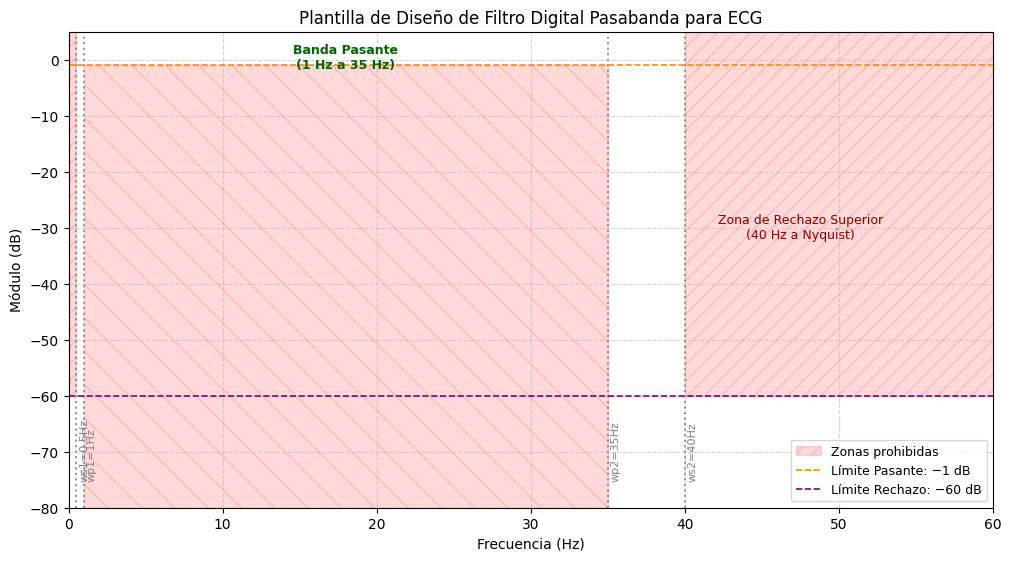

In [11]:
#%% Plantilla y carga de datos
fs_ecg = 1000
nyq_frec = fs_ecg/2
 
ws1 = 0.5 # Hz
wp1 = 1 # Hz
wp2 = 35 # Hz
ws2 = 40 # Hz
gpass = 1 # dB
gstop = 60 # dB

wp = [wp1,wp2]
ws = [ws1,ws2]

# Carga del registro ECG
mat_struct = sio.loadmat('./ECG_TP4.mat')
ecg_lead = mat_struct['ecg_lead'].flatten() * 1.0

# plantilla normalizada a Nyquist en dB
frecs = np.array([0.0, ws1, wp1, wp2, ws2, nyq_frec]) / nyq_frec
gains = np.array([-gstop, -gstop, -gpass, -gpass, -gstop, -gstop]) 
# convertimos a veces para las funciones de diseño
gains = 10**(gains/20)

#%% Grafico de plantilla
# Límites del eje vertical para la gráfica en dB
y_min, y_max = -80.0, 5.0

fig, ax = plt.subplots(figsize=(10, 5.5), constrained_layout=True)

# 1. Zona prohibida: Rechazo Inferior (0 a ws1 Hz, por encima de -gstop dB)
rect_stop1 = Rectangle(
    (0.0, -gstop), ws1, y_max - (-gstop),
    facecolor='red', alpha=0.15, edgecolor='red', hatch='//', label='Zonas prohibidas'
)
ax.add_patch(rect_stop1)

# 2. Zona prohibida: Banda Pasante (wp1 a wp2 Hz, por debajo de -gpass dB)
rect_pass = Rectangle(
    (wp1, y_min), wp2 - wp1, -gpass - y_min,
    facecolor='red', alpha=0.15, edgecolor='red', hatch='\\'
)
ax.add_patch(rect_pass)

# 3. Zona prohibida: Rechazo Superior (ws2 a Nyquist Hz, por encima de -gstop dB)
rect_stop2 = Rectangle(
    (ws2, -gstop), nyq_frec - ws2, y_max - (-gstop),
    facecolor='red', alpha=0.15, edgecolor='red', hatch='//'
)
ax.add_patch(rect_stop2)

# Líneas de referencia para frecuencias límite
for f_cut in [ws1, wp1, wp2, ws2]:
    ax.axvline(f_cut, color='gray', linestyle=':', alpha=0.8)

# Líneas de referencia para niveles de tolerancia en magnitud
ax.axhline(-gpass, color='darkorange', linestyle='--', linewidth=1.2, label=f'Límite Pasante: −{gpass} dB')
ax.axhline(-gstop, color='purple', linestyle='--', linewidth=1.2, label=f'Límite Rechazo: −{gstop} dB')

# Anotaciones textuales de las zonas de interés
ax.text((wp1 + wp2) / 2, -gpass / 2 + 1, f"Banda Pasante\n({wp1} Hz a {wp2} Hz)", 
        ha='center', va='center', fontsize=9, fontweight='bold', color='darkgreen')

ax.text((ws2 + 55) / 2, -gstop / 2, f"Zona de Rechazo Superior\n({ws2} Hz a Nyquist)", 
        ha='center', va='center', fontsize=9, color='darkred')

ax.text(ws1 + 0.2, y_min + 5, f"ws1={ws1}Hz", rotation=90, fontsize=8, color='gray')
ax.text(wp1 + 0.2, y_min + 5, f"wp1={wp1}Hz", rotation=90, fontsize=8, color='gray')
ax.text(wp2 + 0.2, y_min + 5, f"wp2={wp2}Hz", rotation=90, fontsize=8, color='gray')
ax.text(ws2 + 0.2, y_min + 5, f"ws2={ws2}Hz", rotation=90, fontsize=8, color='gray')

# Configuración de ejes (se ajusta xlim a 60 Hz para visualizar en detalle la transición)
ax.set_xlim(0.0, 60.0)
ax.set_ylim(y_min, y_max)
ax.set_xlabel("Frecuencia (Hz)")
ax.set_ylabel("Módulo (dB)")
ax.set_title("Plantilla de Diseño de Filtro Digital Pasabanda para ECG")
ax.grid(True, which='both', linestyle='--', alpha=0.5)
ax.legend(loc='lower right', fontsize=9)

plt.show()

### **Diseño de Filtros Digitales IIR y FIR (Punto c)**

Se implementaron cinco filtros pasabanda utilizando `scipy.signal`:
* **IIR Butterworth (`ftype='butter'`):** Aproximación de máxima planicidad en banda pasante, implementada en secciones de segundo orden (`sos`).
* **IIR Cauer / Elíptico (`ftype='cauer'`):** Aproximación equi-rizada en ambas bandas que minimiza el orden del filtro requerido.
* **FIR por Enventanado (`firwin2`):** Ventana de Hamming con $N = 5001$ coeficientes (Tipo I) para resolver la transición inferior ($\Delta f = 0.5\text{ Hz}$).
* **FIR por Cuadrados Mínimos (`firls`):** Optimización por error cuadrático integrado con $N = 501$ coeficientes (acotado para evitar mal condicionamiento numérico de la matriz de diseño en bajas frecuencias).
* **FIR Parks-McClellan (`remez`):** Algoritmo iterativo equi-rizado (*minimax*) con $N = 501$ coeficientes.

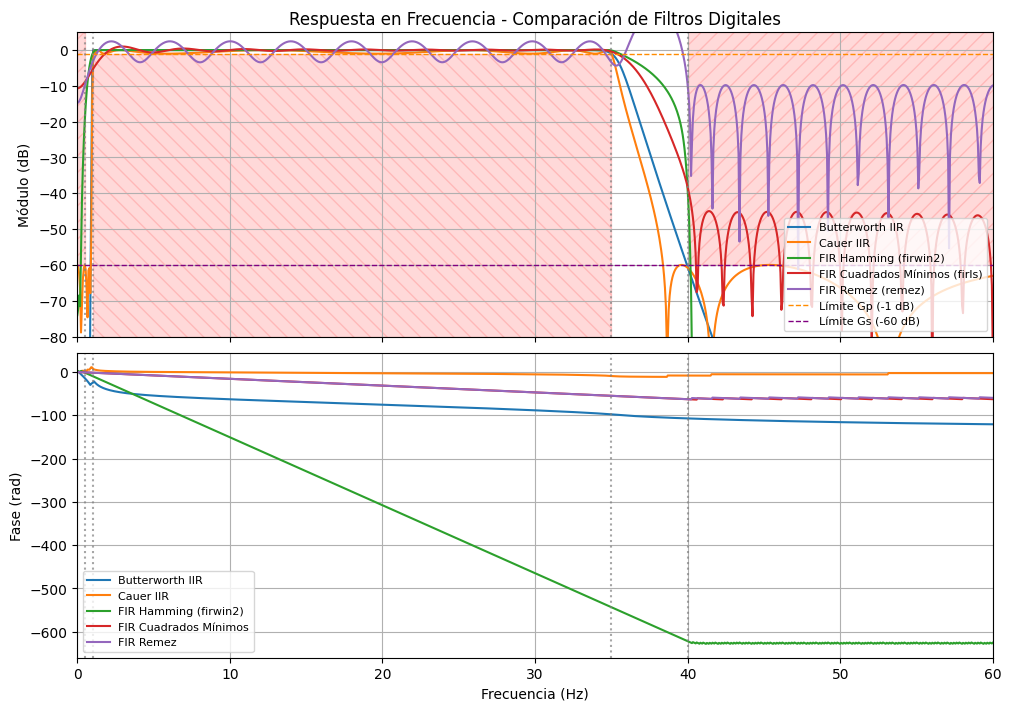

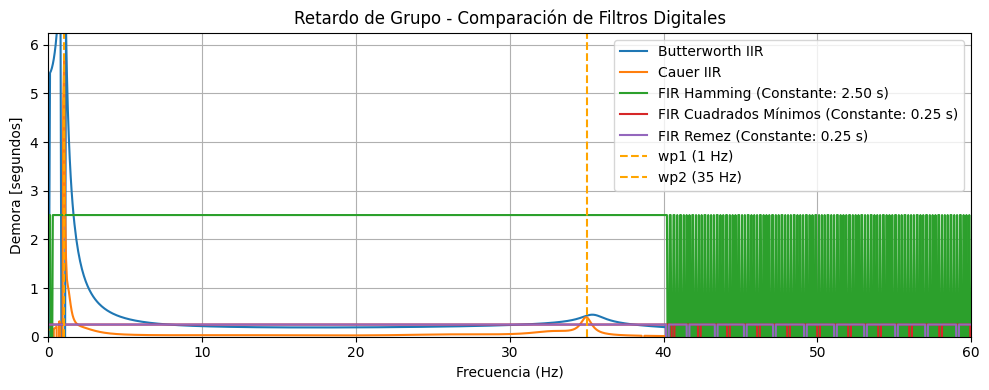

In [13]:
#%% Diseño de Filtro
'''
IIR 1: Pasabanda Butterworth.
IIR 2: Pasabanda Chebyshev II o Cauer.
FIR 1: Pasabanda por Enventanado (firwin).
FIR 2: Pasabanda por Cuadrados Mínimos (firls).
FIR 3: Pasabanda por Parks-McClellan (remez).
'''

# IIR 1: pasabanda butterworth
sos_butt = sig.iirdesign(wp, ws, gpass, gstop, ftype='butter', output='sos', fs=fs_ecg)

# IIR 2: pasabanda Cauer
sos_cauer = sig.iirdesign(wp, ws, gpass, gstop, ftype='cauer', output='sos', fs=fs_ecg)

# parametros para FIR
numtaps_fir = 5001  # Cantidad de coeficientes (debe ser impar para pasabanda Tipo I)
frecs_fir = [0.0, ws1, wp1, wp2, ws2, fs_ecg / 2]
gains_fir = [0.0, 0.0, 1.0, 1.0, 0.0, 0.0]

# FIR 1: Ventana Hamming
b_fir_win = sig.firwin2(numtaps_fir, frecs_fir, gains_fir, window='hamming', fs=fs_ecg)

# FIR 2: Cuadrados minimos
numtaps_ls = 501
b_fir_ls = sig.firls(numtaps_ls, frecs_fir, gains_fir, fs=fs_ecg)

# FIR 3: Parks-McClellan / Remez
numtaps_remez = 501
bands_remez = [0.0, ws1, wp1, wp2, ws2, fs_ecg / 2]
gains_remez = [0.0, 1.0, 0.0]
b_fir_remez = sig.remez(numtaps_remez, bands_remez, gains_remez, fs=fs_ecg)

# Respuesta en frecuencia y retardo de grupo
worN_pts = 8192
# --- Butterworth ---
W_butt, H_butt = sig.sosfreqz(sos_butt, worN=worN_pts, fs=fs_ecg)
modulo_db_butt = 20 * np.log10(np.maximum(np.abs(H_butt), 1e-12))
fase_butt = np.unwrap(np.angle(H_butt))
df_butt = W_butt[1] - W_butt[0]
dw_butt = 2 * np.pi * df_butt
demora_s_butt = -np.gradient(fase_butt, dw_butt)

# --- Cauer ---
W_cauer, H_cauer = sig.sosfreqz(sos_cauer, worN=worN_pts, fs=fs_ecg)
modulo_db_cauer = 20 * np.log10(np.maximum(np.abs(H_cauer), 1e-12))
fase_cauer = np.unwrap(np.angle(H_cauer))
df_cauer = W_cauer[1] - W_cauer[0]
dw_cauer = 2 * np.pi * df_cauer
demora_s_cauer = -np.gradient(fase_cauer, dw_cauer)

# --- FIR Ventana Hamming ---
W_fir_win, H_win = sig.freqz(b_fir_win, a=1.0, worN=worN_pts, fs=fs_ecg)
modulo_db_win = 20 * np.log10(np.maximum(np.abs(H_win), 1e-12))
fase_win = np.unwrap(np.angle(H_win))
df_win = W_fir_win[1] - W_fir_win[0]
dw_win = 2 * np.pi * df_win
demora_s_win = -np.gradient(fase_win, dw_win)

# --- FIR Cuadrados Mínimos ---
W_fir_ls, H_fir_ls = sig.freqz(b_fir_ls, a=1.0, worN=worN_pts, fs=fs_ecg)
modulo_db_fir_ls = 20 * np.log10(np.maximum(np.abs(H_fir_ls), 1e-12))
fase_fir_ls = np.unwrap(np.angle(H_fir_ls))
dw_fir_ls = 2 * np.pi * (W_fir_ls[1] - W_fir_ls[0])
demora_s_fir_ls = -np.gradient(fase_fir_ls, dw_fir_ls)

# --- FIR Parks-McClellan / Remez ---
W_fir_remez, H_fir_remez = sig.freqz(b_fir_remez, a=1.0, worN=worN_pts, fs=fs_ecg)
modulo_db_fir_remez = 20 * np.log10(np.maximum(np.abs(H_fir_remez), 1e-12))
fase_fir_remez = np.unwrap(np.angle(H_fir_remez))
dw_fir_remez = 2 * np.pi * (W_fir_remez[1] - W_fir_remez[0])
demora_s_fir_remez = -np.gradient(fase_fir_remez, dw_fir_remez)

#%% Aplicación de Filtros (Fase Nula)
ecg_filt_butt = sig.sosfiltfilt(sos_butt, ecg_lead)
ecg_filt_cauer = sig.sosfiltfilt(sos_cauer, ecg_lead)
ecg_filt_win = sig.filtfilt(b_fir_win, 1.0, ecg_lead)
ecg_filt_fir_ls = sig.filtfilt(b_fir_ls, 1.0, ecg_lead)
ecg_filt_fir_remez = sig.filtfilt(b_fir_remez, 1.0, ecg_lead)

#%% Visualización
# --- Figura 1: Respuesta en Frecuencia y Fase ---
y_min, y_max = -80.0, 5.0
fig1, ax1 = plt.subplots(2, 1, figsize=(10, 7), sharex=True, constrained_layout=True)

# Módulo
ax1[0].plot(W_butt, modulo_db_butt, label='Butterworth IIR')
ax1[0].plot(W_cauer, modulo_db_cauer, label='Cauer IIR')
ax1[0].plot(W_fir_win, modulo_db_win, label='FIR Hamming (firwin2)')
ax1[0].plot(W_fir_ls, modulo_db_fir_ls, label='FIR Cuadrados Mínimos (firls)')
ax1[0].plot(W_fir_remez, modulo_db_fir_remez, label='FIR Remez (remez)')
ax1[0].set_ylabel('Módulo (dB)')
ax1[0].set_title('Respuesta en Frecuencia - Comparación de Filtros Digitales')
ax1[0].grid(True)
ax1[0].set_ylim(y_min, y_max)

# Plantilla de zonas prohibidas
rect_stop1 = Rectangle((0.0, -gstop), ws1, y_max - (-gstop), facecolor='red', alpha=0.15, edgecolor='red', hatch='//')
rect_pass  = Rectangle((wp1, y_min), wp2 - wp1, -gpass - y_min, facecolor='red', alpha=0.15, edgecolor='red', hatch='\\\\')
rect_stop2 = Rectangle((ws2, -gstop), (fs_ecg / 2) - ws2, y_max - (-gstop), facecolor='red', alpha=0.15, edgecolor='red', hatch='//')
ax1[0].add_patch(rect_stop1)
ax1[0].add_patch(rect_pass)
ax1[0].add_patch(rect_stop2)

ax1[0].axhline(-gpass, color='darkorange', linestyle='--', linewidth=1.0, label=f'Límite Gp (-{gpass} dB)')
ax1[0].axhline(-gstop, color='purple', linestyle='--', linewidth=1.0, label=f'Límite Gs (-{gstop} dB)')
ax1[0].legend(loc='lower right', fontsize=8)

# Fase
ax1[1].plot(W_butt, fase_butt, label='Butterworth IIR')
ax1[1].plot(W_cauer, fase_cauer, label='Cauer IIR')
ax1[1].plot(W_fir_win, fase_win, label='FIR Hamming (firwin2)')
ax1[1].plot(W_fir_ls, fase_fir_ls, label='FIR Cuadrados Mínimos')
ax1[1].plot(W_fir_remez, fase_fir_remez, label='FIR Remez')
ax1[1].set_ylabel('Fase (rad)')
ax1[1].set_xlabel('Frecuencia (Hz)')
ax1[1].set_xlim(0, 60)
ax1[1].grid(True)
ax1[1].legend(loc='lower left', fontsize=8)

for f_cut in [ws1, wp1, wp2, ws2]:
    for axes in ax1:
        axes.axvline(f_cut, color='gray', linestyle=':', alpha=0.7)

plt.show()

# --- Retardo de Grupo ---
plt.figure(figsize=(10, 4))
plt.plot(W_butt, demora_s_butt, label='Butterworth IIR')
plt.plot(W_cauer, demora_s_cauer, label='Cauer IIR')
plt.plot(W_fir_win, demora_s_win, label=f'FIR Hamming (Constante: {(numtaps_fir-1)/(2*fs_ecg):.2f} s)')
plt.plot(W_fir_ls, demora_s_fir_ls, label=f'FIR Cuadrados Mínimos (Constante: {(len(b_fir_ls)-1)/(2*fs_ecg):.2f} s)')
plt.plot(W_fir_remez, demora_s_fir_remez, label=f'FIR Remez (Constante: {(len(b_fir_remez)-1)/(2*fs_ecg):.2f} s)')
plt.axvline(wp1, color='orange', linestyle='--', label=f'wp1 ({wp1} Hz)')
plt.axvline(wp2, color='orange', linestyle='--', label=f'wp2 ({wp2} Hz)')
plt.ylabel("Demora [segundos]")
plt.xlabel("Frecuencia (Hz)")
plt.title("Retardo de Grupo - Comparación de Filtros Digitales")
plt.xlim(0, 60)
plt.ylim(0, np.nanmax(demora_s_cauer[W_cauer <= 60]) * 1.1)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


### **Análisis de Respuesta Espectral y Retardo de Grupo**

* **Cumplimiento de la plantilla:** Los filtros IIR (Butterworth y Cauer) y el FIR enventanado con Hamming ($N=5001$) respetan estrictamente las zonas prohibidas de la plantilla. En contraste, los filtros FIR diseñados mediante `firls` y `remez` con $N=501$ invaden parcialmente las bandas de rechazo debido a que el orden elegido es insuficiente para cubrir una transición de $\Delta f = 0.5\text{ Hz}$ a $f_s = 1000\text{ Hz}$.
* **Comportamiento de fase y retardo de grupo:** Los filtros FIR exhiben fase lineal exacta y retardo de grupo constante ($\tau_g = \frac{N-1}{2f_s}$). Los filtros IIR presentan retardo de grupo no lineal con picos pronunciados en los bordes de la banda pasante ($1\text{ Hz}$ y $35\text{ Hz}$), efecto que es neutralizado en el procesamiento posterior mediante el uso de `sosfiltfilt`.

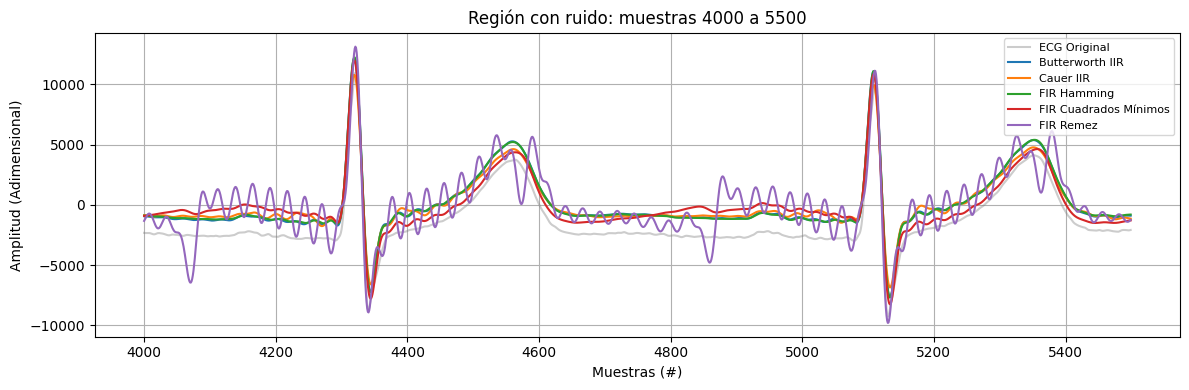

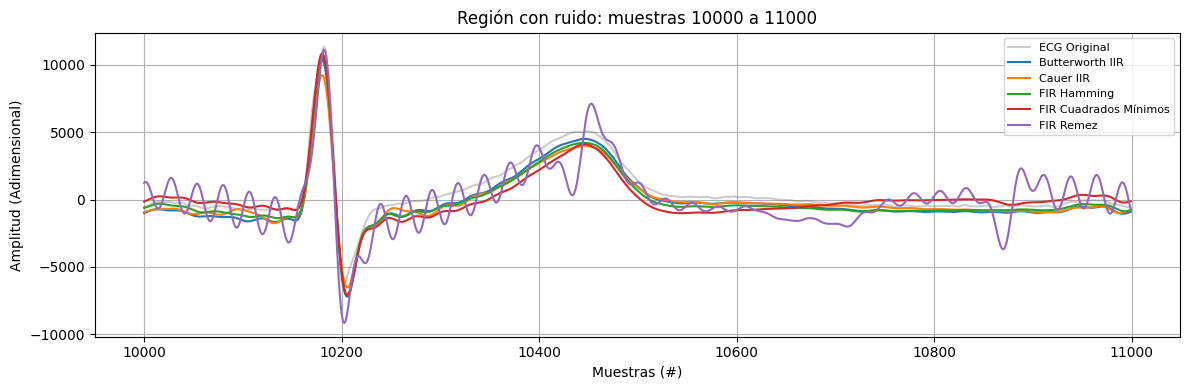

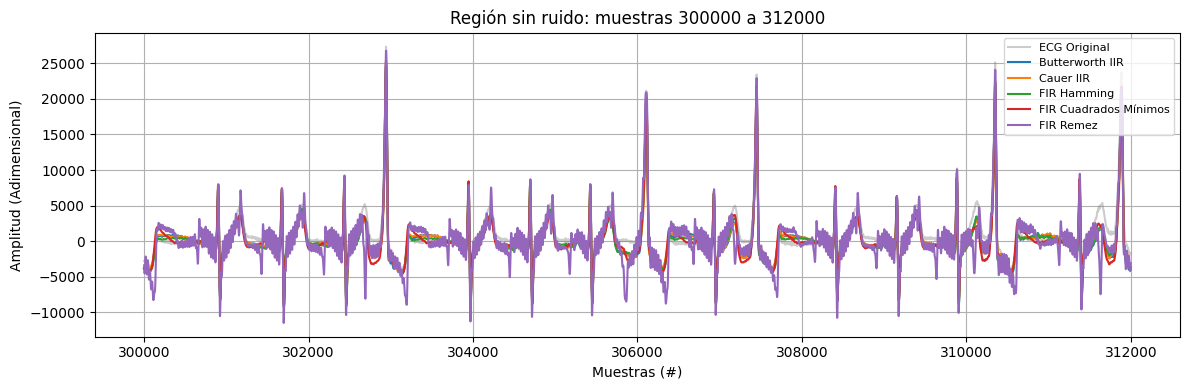

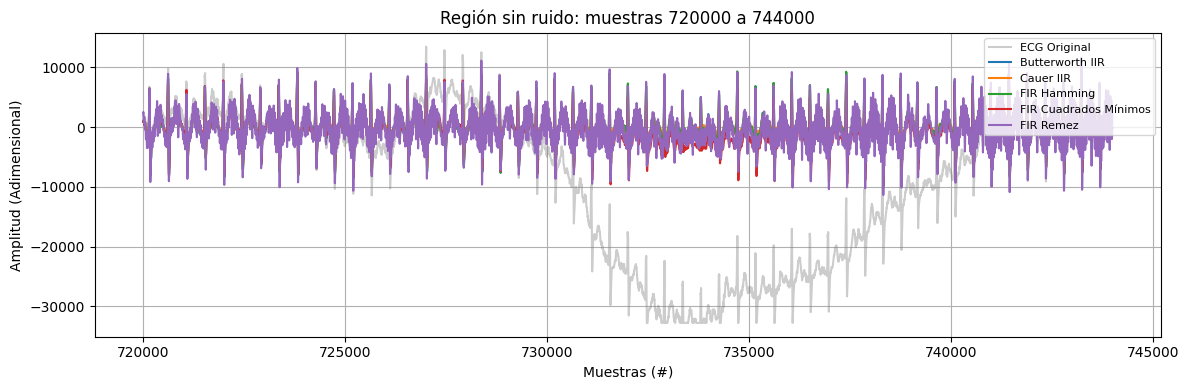

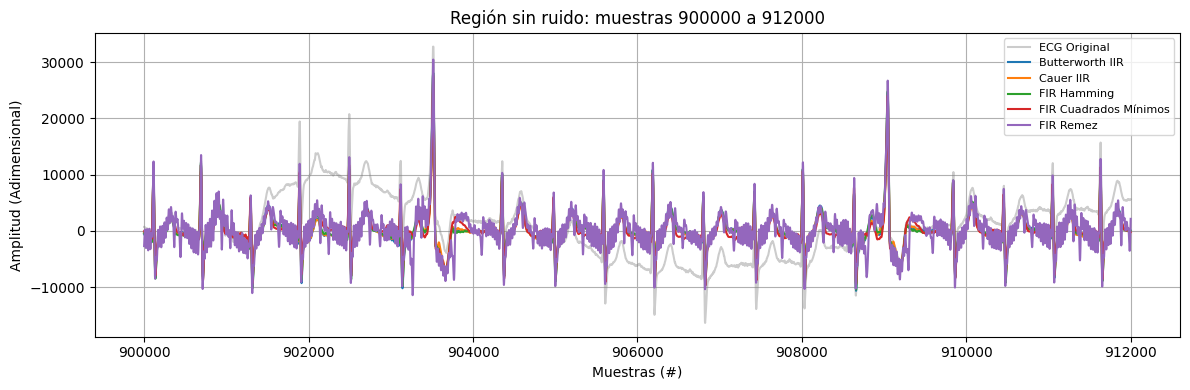

In [14]:
#%% --- Análisis en regiones de interés ---
cant_muestras = ecg_lead.shape[0]

# Regiones de interés con ruido
regs_ruido = (
    [4000, 5500],     # muestras
    [10e3, 11e3],     # muestras
)

for ii in regs_ruido:
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')
    
    plt.figure(figsize=(12, 4))
    plt.plot(zoom_region, ecg_lead[zoom_region], label='ECG Original', alpha=0.4, color='gray')
    plt.plot(zoom_region, ecg_filt_butt[zoom_region], label='Butterworth IIR')
    plt.plot(zoom_region, ecg_filt_cauer[zoom_region], label='Cauer IIR')
    plt.plot(zoom_region, ecg_filt_win[zoom_region], label='FIR Hamming')
    plt.plot(zoom_region, ecg_filt_fir_ls[zoom_region], label='FIR Cuadrados Mínimos')
    plt.plot(zoom_region, ecg_filt_fir_remez[zoom_region], label='FIR Remez')
    
    plt.title(f'Región con ruido: muestras {int(ii[0])} a {int(ii[1])}')
    plt.ylabel('Amplitud (Adimensional)')
    plt.xlabel('Muestras (#)')
    plt.grid(True)
    plt.legend(loc='upper right', fontsize=8)
    plt.tight_layout()
    plt.show()

# Regiones de interés sin ruido
regs_limpias = (
    np.array([5, 5.2]) * 60 * fs_ecg,     # minutos a muestras
    np.array([12, 12.4]) * 60 * fs_ecg,   # minutos a muestras
    np.array([15, 15.2]) * 60 * fs_ecg,   # minutos a muestras
)

for ii in regs_limpias:
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')
    
    plt.figure(figsize=(12, 4))
    plt.plot(zoom_region, ecg_lead[zoom_region], label='ECG Original', alpha=0.4, color='gray')
    plt.plot(zoom_region, ecg_filt_butt[zoom_region], label='Butterworth IIR')
    plt.plot(zoom_region, ecg_filt_cauer[zoom_region], label='Cauer IIR')
    plt.plot(zoom_region, ecg_filt_win[zoom_region], label='FIR Hamming')
    plt.plot(zoom_region, ecg_filt_fir_ls[zoom_region], label='FIR Cuadrados Mínimos')
    plt.plot(zoom_region, ecg_filt_fir_remez[zoom_region], label='FIR Remez')
    
    plt.title(f'Región sin ruido: muestras {int(ii[0])} a {int(ii[1])}')
    plt.ylabel('Amplitud (Adimensional)')
    plt.xlabel('Muestras (#)')
    plt.grid(True)
    plt.legend(loc='upper right', fontsize=8)
    plt.tight_layout()
    plt.show()


### **Evaluación de Desempeño**

**Desempeño en zonas contaminadas (`[4000, 5500]` y `[10000, 11000]`):**
   * Los filtros **Butterworth**, **Cauer** y **FIR Hamming** logran remover eficazmente la deriva de línea de base, estabilizando los segmentos isoeléctricos alrededor de cero, y suavizan las oscilaciones de alta frecuencia de origen muscular.
   * Los filtros **FIR Cuadrados Mínimos** y **FIR Remez** ($N=501$) exhiben rizado residual superpuesto sobre la señal y atenuación incompleta de la deriva lenta, producto de su subdimensionamiento frente a la transición en $0.5\text{ Hz}$.

**Inocuidad en zonas limpias (minutos 5, 12 y 15):**
   * Gracias al filtrado bidireccional de fase nula (`sosfiltfilt` / `filtfilt`), no se introducen desplazamientos temporales en los complejos QRS ni deformaciones asimétricas en las ondas P y T.
   * Se observa una leve reducción en la amplitud máxima de los picos R (esperable al limitar el espectro por encima de $35\text{ Hz}$) y pequeñas oscilaciones transitorias (*ringing* por fenómeno de Gibbs) adyacentes a las pendientes abruptas del QRS.


### **Conclusiones**
**Conclusión comparativa:** Para el procesamiento *offline* de este registro de ECG, las aproximaciones **IIR Butterworth y Cauer** aplicadas con `sosfiltfilt` ofrecen el mejor compromiso entre cumplimiento estricto de la plantilla, fidelidad morfológica (comparada con la señal ECG sin ruido) y bajo costo computacional frente a los filtros FIR de orden elevado.